# Упражнения по регуляризации и методу градиентного спуска

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import (LinearRegression, Ridge, RidgeCV, ElasticNet,
                                  LassoCV, lasso_path, SGDRegressor)
from sklearn.metrics import mean_squared_error, mean_absolute_error

## Вопрос 1: Генерация нелинейных данных с гетероскедастичным шумом

В реальных задачах шум в данных часто зависит от значения входных признаков (гетероскедастичность).

* Сгенерируйте 250 равномерно распределенных точек $x$ на отрезке $[0, 5]$.
* Вычислите истинное значение целевой переменной по формуле: $y_{\\text{true}} = 2.5 \\cdot \\sin(1.5 x) + 0.3 x^2 - 1.5$.

* Добавьте гауссов шум, дисперсия которого растет линейно с ростом $x$: $\\sigma(x) = 0.15 \\cdot (1 + 0.8x)$.

* Разделите данные на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.
* Постройте график тренировочных, тестовых точек и истинной функции.

In [4]:
rng = np.random.default_rng(42)

x = rng.uniform(0, 5, 250)
y_true = 2.5 * np.sin(1.5 * x) + 0.3 * x**2 - 1.5
sigma = 0.15 * (1 + 0.8 * x)
y = y_true + rng.normal(0, sigma)

X = x.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

(175, 1) (75, 1)


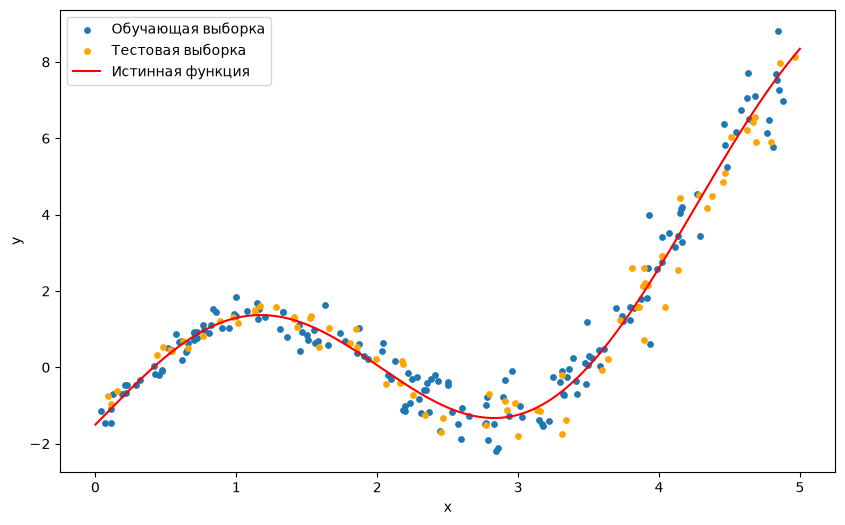

In [5]:
x_line = np.linspace(0, 5, 500)
y_line = 2.5 * np.sin(1.5 * x_line) + 0.3 * x_line**2 - 1.5

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, s=15, label="Обучающая выборка")
plt.scatter(X_test, y_test, s=15, color="orange", label="Тестовая выборка")
plt.plot(x_line, y_line, color="red", label="Истинная функция")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## Вопрос 2: Исследование полиномов высокой степени и феномена Рунге

При слишком высокой степени полинома модель стремится идеально пройти через все точки обучающей выборки, образуя сильные осцилляции на краях интервала.

* Сформируйте полиномиальные признаки 25-й степени (`degree=25`).

* Обучите обычную линейную регрессию (`LinearRegression`) без регуляризации.

* Оцените $RMSE$ на обучающей и тестовой выборках.

Постройте график предсказаний модели на всем отрезке $[0, 5]$. Проанализируйте осцилляции модели на границах интервала.

In [6]:
pf = PolynomialFeatures(25)
X_train_poly = pf.fit_transform(X_train)
X_test_poly = pf.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_poly, y_train)

rmse_train = np.sqrt(mean_squared_error(y_train, lr.predict(X_train_poly)))
rmse_test = np.sqrt(mean_squared_error(y_test, lr.predict(X_test_poly)))
print(f"RMSE train: {rmse_train:.4f}")
print(f"RMSE test:  {rmse_test:.4f}")

RMSE train: 0.9276
RMSE test:  1.3464


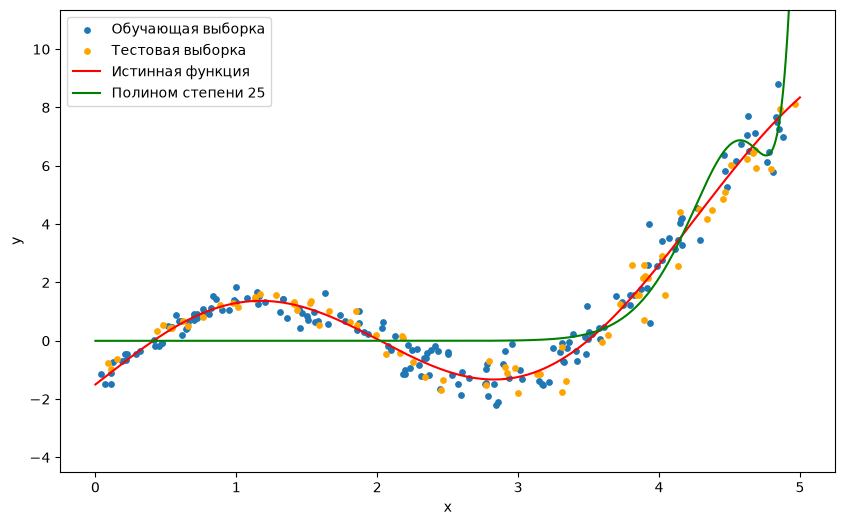

In [7]:
y_line_pred = lr.predict(pf.transform(x_line.reshape(-1, 1)))

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, s=15, label="Обучающая выборка")
plt.scatter(X_test, y_test, s=15, color="orange", label="Тестовая выборка")
plt.plot(x_line, y_line, color="red", label="Истинная функция")
plt.plot(x_line, y_line_pred, color="green", label="Полином степени 25")
plt.ylim(y_line.min() - 3, y_line.max() + 3)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Вывод.** RMSE на обучении 0.93, на тесте 1.35 — на новых данных модель хуже. На правом краю (x → 5) кривая резко уходит вверх и осциллирует (феномен Рунге), а на участке [0, 3] она «прилипает» к нулю: при степени 25 значения x^25 огромны, и задача численно неустойчива.

## Вопрос 3: Диагностика Bias-Variance с помощью кривых обучения (Learning Curves)

Кривые обучения позволяют определить, принесет ли пользу добавление новых данных или необходима регуляризация.\

* Напишите функцию для расчета и построения кривых обучения с помощью `learning_curve` из `sklearn.model_selection`.

* Постройте кривые обучения для неуправляемой линейной регрессии (степень 15) и Ridge-регрессии (степень 15, $\\alpha = 1.0$).

* Объясните разрыв (*generalization gap*) между ошибкой на обучении и валидации для обеих моделей."

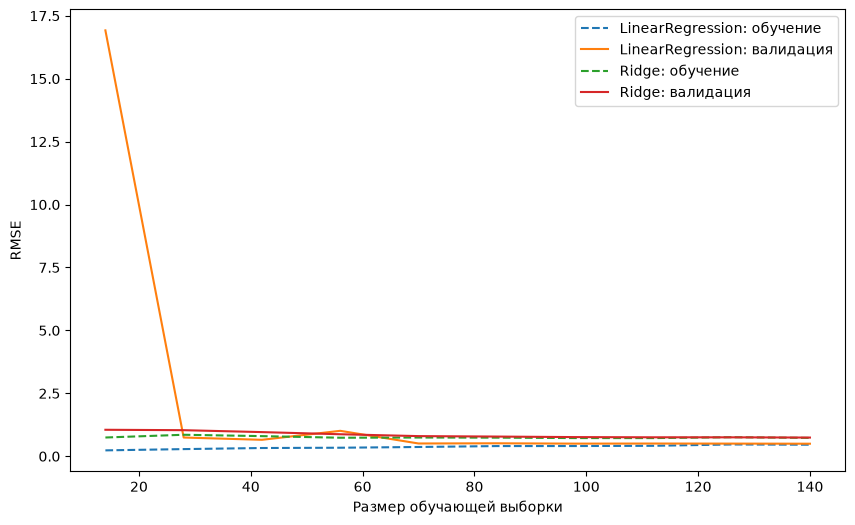

In [8]:
def plot_learning_curve(model, X, y, label):
    sizes, train_scores, val_scores = learning_curve(
        model, X, y, train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5, scoring="neg_mean_squared_error")
    plt.plot(sizes, np.sqrt(-train_scores.mean(axis=1)), "--", label=f"{label}: обучение")
    plt.plot(sizes, np.sqrt(-val_scores.mean(axis=1)), "-", label=f"{label}: валидация")


model_lr = make_pipeline(PolynomialFeatures(15), StandardScaler(), LinearRegression())
model_ridge = make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=1.0))

plt.figure(figsize=(10, 6))
plot_learning_curve(model_lr, X_train, y_train, "LinearRegression")
plot_learning_curve(model_ridge, X_train, y_train, "Ridge")
plt.xlabel("Размер обучающей выборки")
plt.ylabel("RMSE")
plt.legend()
plt.show()

**Вывод.** У обычной регрессии ошибка на обучении ниже, чем на валидации, а при малой выборке ошибка валидации огромная (≈17): модель запоминает шум (высокая дисперсия, переобучение). С ростом данных разрыв (generalization gap) сокращается. У Ridge кривые обучения и валидации почти совпадают, разрыв минимален: штраф на веса не даёт подогнаться под шум, за это платим чуть большей ошибкой на обучении (небольшое смещение).

## Вопрос 4: Подготовка продвинутых признаков и обработка Ames Housing

Перейдем к реальному набору данных о продажах недвижимости `Ames_Housing_Sales.csv`.

* Загрузите датасет, выполните One-Hot Encoding категориальных признаков.

* Проверьте признаки на асимметрию (`skew > 0.75`) и примените преобразование `np.log1p`.

* Создайте парные взаимодействия признаков только для ключевых числовых переменных (`LotArea`, `GrLivArea`, `TotalBsmtSF`), используя `PolynomialFeatures(interaction_only=True)`.\

Разделите данные на обучающую и тестовую выборки (70/30).

In [9]:
data = pd.read_csv("data/Ames_Housing_Sales.csv")

# пропуски: числа -> медиана, категории -> отдельная категория "None"
num_cols = [c for c in data.select_dtypes(include=[np.number]).columns if c != "SalePrice"]
cat_cols = data.select_dtypes(exclude=[np.number]).columns.tolist()
data[num_cols] = data[num_cols].fillna(data[num_cols].median())
data[cat_cols] = data[cat_cols].fillna("None")
data = data.dropna(subset=["SalePrice"])

# One-Hot Encoding
data = pd.get_dummies(data, columns=cat_cols, dtype=int)
print(data.shape)

(1379, 295)


In [10]:
train, test = train_test_split(data, test_size=0.3, random_state=42)
train, test = train.copy(), test.copy()

In [11]:
# признаки с асимметрией считаем по обучающей выборке
skew = train[num_cols].skew()
skew_cols = skew[skew.abs() > 0.75].index.tolist()
print(len(skew_cols), "признаков с |skew| > 0.75")

23 признаков с |skew| > 0.75


In [12]:
for col in skew_cols:
    train[col] = np.log1p(train[col])
    test[col] = np.log1p(test[col])

In [13]:
key_cols = ["LotArea", "GrLivArea", "TotalBsmtSF"]

pf = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
pf.fit(train[key_cols])
names = pf.get_feature_names_out(key_cols)
new_names = [n for n in names if " " in n]   # только попарные произведения

for df in (train, test):
    inter = pd.DataFrame(pf.transform(df[key_cols]), columns=names, index=df.index)
    df[new_names] = inter[new_names]
print(new_names)

['LotArea GrLivArea', 'LotArea TotalBsmtSF', 'GrLivArea TotalBsmtSF']


In [14]:
feature_cols = [c for c in train.columns if c != "SalePrice"]
X_train_ames = train[feature_cols].to_numpy()
y_train_ames = train["SalePrice"].to_numpy()
X_test_ames = test[feature_cols].to_numpy()
y_test_ames = test["SalePrice"].to_numpy()
print(X_train_ames.shape, X_test_ames.shape)

(965, 297) (414, 297)


## Вопрос 5: Двумерный сетчатый поиск гиперпараметров ElasticNet с GridSearchCV

Регрессия `ElasticNet` комбинирует $L_1$ и $L_2$ штрафы через два ключевых гиперпараметра: $\\alpha$ (сила регуляризации) и `l1_ratio` (доля $L_1$-штрафа).

* Настройте сетку параметров: `alpha`: `[1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0]`, `l1_ratio`: `[0.1, 0.3, 0.5, 0.7, 0.9]`.

* Запустите `GridSearchCV` с 5-кратной кросс-валидацией (`cv=5`) и метрикой `neg_root_mean_squared_error`.

* Визуализируйте результаты сетчатого поиска в виде тепловой карты (`sns.heatmap`).

* Выведите оптимальные параметры и оцените итоговое $RMSE$ на тестовой выборке."

In [15]:
import warnings
warnings.filterwarnings("ignore")   # убираем предупреждения о сходимости

param_grid = {
    "model__alpha": [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0],
    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
}
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(max_iter=5000)),
])
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="neg_root_mean_squared_error")
grid.fit(X_train_ames, y_train_ames)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=5000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.0001, 0.001, ...], 'model__l1_ratio': [0.1, 0.3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

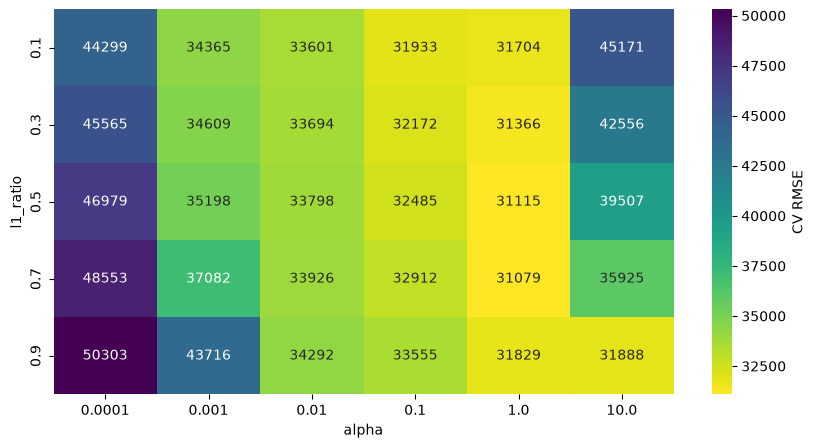

In [16]:
results = pd.DataFrame(grid.cv_results_)
results["rmse"] = -results["mean_test_score"]
heat = results.pivot(index="param_model__l1_ratio", columns="param_model__alpha", values="rmse").astype(float)

plt.figure(figsize=(10, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="viridis_r", cbar_kws={"label": "CV RMSE"})
plt.xlabel("alpha")
plt.ylabel("l1_ratio")
plt.show()

In [17]:
print("Лучшие параметры:", grid.best_params_)
print(f"Лучший CV RMSE: {-grid.best_score_:.0f}")
y_pred = grid.predict(X_test_ames)
print(f"RMSE на тесте:  {np.sqrt(mean_squared_error(y_test_ames, y_pred)):.0f}")

Лучшие параметры: {'model__alpha': 1.0, 'model__l1_ratio': 0.7}
Лучший CV RMSE: 31079
RMSE на тесте:  33930


**Вывод.** Лучшие параметры: alpha = 1.0, l1_ratio = 0.7. CV RMSE ≈ 31079, RMSE на тесте ≈ 33930. При очень малом alpha (почти нет регуляризации) ошибка заметно выше, при alpha = 10 для малых l1_ratio — тоже растёт (слишком сильное сжатие).

## Вопрос 6: Анализ разряженности (Sparsity) моделей Lasso и отбор признаков

$L_1$-регуляризация способна занулять коэффициенты неинформативных признаков.

* Обучите модель `LassoCV` с диапазоном `alphas = np.logspace(-4, 1, 50)`.

* Постройте график зависимости количества ненулевых коэффициентов от значения $\\alpha$.
* Выделите ТОП-10 наиболее важных признаков с наибольшими абсолютными значениями коэффициентов при оптимальном $\\alpha$.
* Какая доля признаков была полностью исключена из модели?

In [18]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_ames)
X_test_s = scaler.transform(X_test_ames)

alphas = np.logspace(-4, 1, 50)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=20000)
lasso_cv.fit(X_train_s, y_train_ames)
print("Оптимальный alpha:", lasso_cv.alpha_)

Оптимальный alpha: 10.0


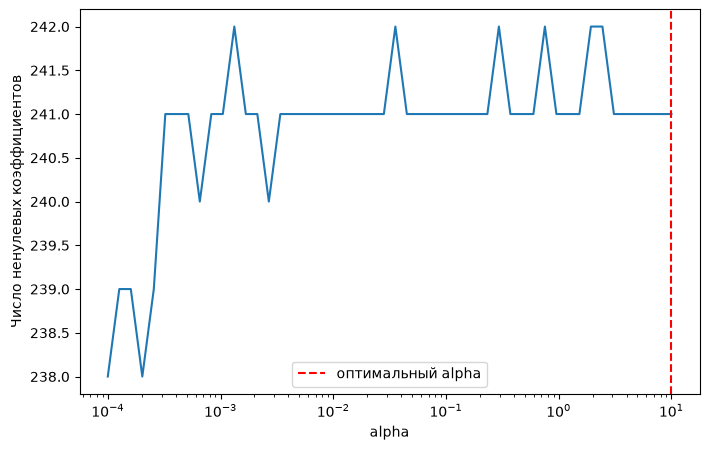

In [19]:
# число ненулевых коэффициентов для каждого alpha
_, coefs, _ = lasso_path(X_train_s, y_train_ames, alphas=alphas, max_iter=20000)
n_nonzero = (coefs != 0).sum(axis=0)

plt.figure(figsize=(8, 5))
plt.semilogx(alphas, n_nonzero)
plt.axvline(lasso_cv.alpha_, color="red", linestyle="--", label="оптимальный alpha")
plt.xlabel("alpha")
plt.ylabel("Число ненулевых коэффициентов")
plt.legend()
plt.show()

In [20]:
coef = pd.Series(lasso_cv.coef_, index=feature_cols)
print("ТОП-10 признаков:")
print(coef.abs().sort_values(ascending=False).head(10).index.map(lambda n: f"{n}: {coef[n]:.0f}").to_list())

share_zero = (coef == 0).mean()
print(f"Исключено признаков: {(coef == 0).sum()} из {len(coef)} ({share_zero:.1%})")

ТОП-10 признаков:
['LotArea GrLivArea: 231828', 'LotArea: -163051', 'GrLivArea: -114912', 'TotalBsmtSF: -102435', 'GrLivArea TotalBsmtSF: 62082', 'LotArea TotalBsmtSF: 54089', 'PoolQC_Gd: -21214', 'BsmtFinSF1: 11519', 'MiscVal: 11459', 'YearBuilt: 11061']
Исключено признаков: 56 из 297 (18.9%)


**Вывод.** Оптимальный alpha = 10 — это край заданной сетки. Исключено 56 из 297 признаков (18.9%). Самые важные — признаки площади и их взаимодействия (LotArea, GrLivArea, TotalBsmtSF). График почти плоский: цена ~10^5, поэтому alpha из диапазона [1e-4, 10] слишком малы, чтобы занулить много коэффициентов.

## Вопрос 7: Настройка схем скорости обучения (Learning Rate Schedules) в SGDRegressor

Алгоритм стохастического градиентного спуска критически чувствителен к масштабу данных и выбору правила изменения шага $\\eta$.

* Отсштабируйте признаки `X_train_ames` и `X_test_ames` с помощью `StandardScaler`.

Обучите четыре версии `SGDRegressor` с регуляризацией `penalty='elasticnet'`, используя различные стратегии `learning_rate`:

1. `'constant'` (`eta0=0.01`)

2. `'optimal'`

3. `'invscaling'` (`eta0=0.01`, `power_t=0.25`)

4. `'adaptive'` (`eta0=0.01`)

* Сравните полученные значения $RMSE$ и общее число итераций до сходимости (`n_iter_`).

In [21]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_ames)
X_test_s = scaler.transform(X_test_ames)

# SGD чувствителен к масштабу и целевой переменной, поэтому стандартизуем y
y_mean, y_std = y_train_ames.mean(), y_train_ames.std()
y_train_s = (y_train_ames - y_mean) / y_std

schedules = {
    "constant":   dict(learning_rate="constant", eta0=0.01),
    "optimal":    dict(learning_rate="optimal"),
    "invscaling": dict(learning_rate="invscaling", eta0=0.01, power_t=0.25),
    "adaptive":   dict(learning_rate="adaptive", eta0=0.01),
}
for name, params in schedules.items():
    sgd = SGDRegressor(penalty="elasticnet", random_state=42, **params)
    sgd.fit(X_train_s, y_train_s)
    pred = sgd.predict(X_test_s) * y_std + y_mean
    rmse = np.sqrt(mean_squared_error(y_test_ames, pred))
    print(f"{name:11s} RMSE = {rmse:12.0f}   n_iter_ = {sgd.n_iter_}")

constant    RMSE = 204479096992196000   n_iter_ = 6
optimal     RMSE = 2414915105983011328   n_iter_ = 68
invscaling  RMSE =      9498794   n_iter_ = 6
adaptive    RMSE = 25315167306028920   n_iter_ = 36


**Вывод.** Число итераций: constant — 6, optimal — 68, invscaling — 6, adaptive — 36. Во всех схемах SGD расходится (RMSE огромный; лучшая — invscaling, у неё шаг уменьшается со временем). Причина: шаг 0.01 слишком велик, а у редких one-hot признаков после масштабирования значения достигают ~31, и квадратичный градиент «взрывается». Для реального качества нужен меньший eta0.

## Вопрос 8: Сравнительный анализ устойчивости моделей к выбросам (Outliers)

Среднеквадратичная ошибка ($MSE$) в оптимизации градиентным спуском квадратично штрафует отклонения, делая модели чувствительными к аномалиям.

* Добавьте в 5% случайных точек обучающей выборки `y_train_ames` аномальные выбросы (увеличьте их значение в 3 раза).

* Обучите следующие модели на искаженных данных:

1. OLS (`LinearRegression`)
2. Ridge (`RidgeCV`)     
3. SGDRegressor с функциями потерь `loss='squared_error'` ($L_2$) и `loss='huber'` (Huber loss, комбинирующий $L_1$ и $L_2$).

* Оцените $RMSE$ и $MAE$ каждой модели на чистой тестовой выборке `y_test_ames`.

Сделайте выводы об устойчивости функции потерь Хьюбера по сравнению с классической регрессией.

     

In [22]:
rng = np.random.default_rng(42)
y_train_out = y_train_ames.copy()
idx = rng.choice(len(y_train_out), size=int(0.05 * len(y_train_out)), replace=False)
y_train_out[idx] *= 3

y_mean, y_std = y_train_out.mean(), y_train_out.std()
y_train_out_s = (y_train_out - y_mean) / y_std

models = {
    "OLS": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=np.logspace(-2, 3, 20)),
    "SGD squared_error": SGDRegressor(loss="squared_error", random_state=42),
    "SGD huber": SGDRegressor(loss="huber", random_state=42),
}
for name, model in models.items():
    model.fit(X_train_s, y_train_out_s)
    pred = model.predict(X_test_s) * y_std + y_mean
    rmse = np.sqrt(mean_squared_error(y_test_ames, pred))
    mae = mean_absolute_error(y_test_ames, pred)
    print(f"{name:18s} RMSE = {rmse:9.0f}   MAE = {mae:9.0f}")

OLS                RMSE =    572182   MAE =     83999
RidgeCV            RMSE =     41052   MAE =     29101
SGD squared_error  RMSE =   9282837   MAE =   2629879
SGD huber          RMSE =     33261   MAE =     20181


**Вывод.** OLS (RMSE 572182, MAE 83999) и SGD с квадратичной потерей (RMSE ≈ 9.3 млн) сильно портятся от выбросов, т.к. ошибка возводится в квадрат. RidgeCV устойчивее (RMSE 41052, MAE 29101) за счёт регуляризации. SGD с Huber loss лучший (RMSE 33261, MAE 20181): для больших ошибок потеря линейна, и выбросы влияют слабо.